<a href="https://colab.research.google.com/github/SaronJenish/CSA4703---Deep-Learning/blob/main/Experiment_01_Vector_and_Matrix_Operations_for_Deep_Learning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Experiment 1: Vector and Matrix Operations for Deep Learning

CSA47 – Deep Learning. Run the setup cell first, then execute the experiment cells in order.


In [1]:
# Common setup – run this cell first
import os, time, warnings, math
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, mean_absolute_error, mean_squared_error)
np.random.seed(42)
plt.rcParams["figure.figsize"] = (7, 4)
print("Setup complete")

Setup complete


## Experiment 1 – Vector and Matrix Operations for Deep Learning

Customer-Genre (6x5):
 [[4. 5. 3. 5. 5.]
 [2. 3. 3. 3. 5.]
 [4. 3. 5. 2. 4.]
 [2. 4. 5. 1. 4.]
 [2. 5. 4. 1. 1.]
 [3. 3. 2. 4. 4.]]

Genre-Book (5x4):
 [[0.37 0.46 0.79 0.2 ]
 [0.51 0.59 0.05 0.61]
 [0.17 0.07 0.95 0.97]
 [0.81 0.3  0.1  0.68]
 [0.44 0.12 0.5  0.03]]

Customer-book scores:
 [[10.79  7.11  9.18 10.33]
 [ 7.41  4.41  7.33  7.34]
 [ 7.24  5.02 10.2   8.96]
 [ 6.21  4.4   8.58  8.48]
 [ 5.23  4.56  6.19  8.02]
 [ 7.98  4.98  6.76  7.23]]

Dot product (customer 1, customer 2): 72.0

Transpose:
 [[4. 2. 4. 2. 2. 3.]
 [5. 3. 3. 4. 5. 3.]
 [3. 3. 5. 5. 4. 2.]
 [5. 3. 2. 1. 1. 4.]
 [5. 5. 4. 4. 1. 4.]]

Element-wise square:
 [[16. 25.  9. 25. 25.]
 [ 4.  9.  9.  9. 25.]
 [16.  9. 25.  4. 16.]
 [ 4. 16. 25.  1. 16.]
 [ 4. 25. 16.  1.  1.]
 [ 9.  9.  4. 16. 16.]]

Inverse of valid square matrix (Gram + I):
 [[ 0.42744857 -0.14683855 -0.00638684  0.08962263 -0.14919192 -0.39730567]
 [-0.14683855  0.49309586  0.04100793 -0.3191534   0.17551754 -0.16081979]
 [-0.00638684  0.04100793

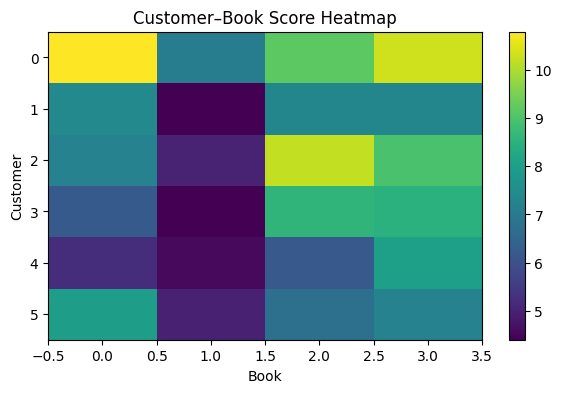

In [2]:
# 1. Build matrices, operations, cosine similarity, dense layer and heatmap
customer_genre = np.random.randint(1, 6, size=(6, 5)).astype(float)
genre_book = np.random.rand(5, 4)
print("Customer-Genre (6x5):\n", customer_genre)
print("\nGenre-Book (5x4):\n", np.round(genre_book, 2))
scores = customer_genre @ genre_book
print("\nCustomer-book scores:\n", np.round(scores, 2))
print("\nDot product (customer 1, customer 2):", np.dot(customer_genre[0], customer_genre[1]))
print("\nTranspose:\n", customer_genre.T)
print("\nElement-wise square:\n", customer_genre ** 2)
print("\nInverse of valid square matrix (Gram + I):\n", np.linalg.inv(customer_genre @ customer_genre.T + np.eye(6)))
norms = np.linalg.norm(customer_genre, axis=1, keepdims=True)
cosine = (customer_genre @ customer_genre.T) / (norms @ norms.T)
np.fill_diagonal(cosine, -1)
i, j = np.unravel_index(np.argmax(cosine), cosine.shape)
print(f"Most similar customers: {i+1} and {j+1}; cosine similarity={cosine[i,j]:.3f}")
x = customer_genre[0]
W, b = np.random.randn(3, 5), np.random.randn(3)
print("\nDense layer y=Wx+b:", W @ x + b)
plt.imshow(scores, cmap="viridis", aspect="auto"); plt.colorbar()
plt.xlabel("Book"); plt.ylabel("Customer"); plt.title("Customer–Book Score Heatmap"); plt.show()